# 01 - Autoencoder recurrente: código en cada paso y cierre del ciclo

Se compara el autoencoder GRU del proyecto NeuroStrideAI (original) con la versión refinada, que entrega el código latente en cada paso del decodificador y penaliza el salto entre la primera y la última fase. La formulación está en `docs/formulacion.md`.

$$\mathcal{L} = \frac{1}{606N}\sum_i \Vert \hat Z_i - Z_i\Vert_F^2 + w\,\frac{1}{6N}\sum_{i,j}\left|\hat Z_i^{(j)}(0)-\hat Z_i^{(j)}(1)\right|$$

El modelo A se entrena con ciclos limpios; el modelo B, con ciclos corruptos y objetivo limpio. Cada variante se entrena con cinco semillas.

In [1]:
# Requiere: pip install -e . desde la raíz del repositorio
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cycle_manifold import SEEDS, SPECS, load_cycle_data
from cycle_manifold.data import find_cycles_file

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data = load_cycle_data(find_cycles_file())
OUT = REPO / "results" / "gru_refinement"
print({k: v.shape for k, v in data.X.items()})

{'train': (240, 101, 6), 'validation': (44, 101, 6), 'control_test': (47, 101, 6), 'case_external_test': (130, 101, 6)}


## 1. Una corrida rápida (semilla 42)

In [2]:
from cycle_manifold.evaluation import evaluate
from cycle_manifold.training import fit_gru, predict_gru

rows = {}
for name in ("A_original", "A_refined"):
    model = fit_gru(data, SPECS[name], seed=42)
    rows[name] = evaluate(data, lambda z, m=model: predict_gru(m, z))
pd.DataFrame(rows).T[["mae_deg", "endpoint_jump_deg", "correction_gain", "typicality_gain"]].round(3)

,mae_deg,endpoint_jump_deg,correction_gain,typicality_gain
A_original,4.789,4.911,0.223,0.346
A_refined,4.038,0.968,0.209,0.333


## 2. Protocolo completo

La celda siguiente lee los resultados guardados por `python -m cycle_manifold gru --out ...`. Si no existen, ejecuta el protocolo completo (aproximadamente 15 minutos en CPU).

In [3]:
import json
from cycle_manifold.experiments import run_gru_benchmark
from cycle_manifold.statistics import summarize, paired_test

saved = OUT / "gru_per_seed.json"
if saved.exists():
    results = json.loads(saved.read_text(encoding="utf-8"))
else:
    results, _, _ = run_gru_benchmark(data, out_dir=OUT)
summary = summarize(results)
summary[[c for c in summary.columns if c.startswith(("mae", "endpoint", "correction"))]].round(3)

,mae_deg_mean,mae_deg_std,mae_deg_ensemble,endpoint_jump_deg_mean,endpoint_jump_deg_std,endpoint_jump_deg_ensemble,correction_gain_mean,correction_gain_std,correction_gain_ensemble
model,,,,,,,,,
A_original,4.991,0.229,4.811,5.066,0.549,4.500,0.208,0.018,0.249
B_original,5.245,0.101,5.188,3.044,0.312,2.717,0.296,0.014,0.305
A_refined,4.113,0.049,3.906,0.866,0.106,0.548,0.189,0.012,0.229
B_refined,4.827,0.074,4.743,0.567,0.045,0.363,0.337,0.007,0.349


## 3. Pruebas pareadas: refinado frente a original

In [4]:
for kind in ("A", "B"):
    print(f"Modelo {kind}")
    display(paired_test(results[f"{kind}_refined"], results[f"{kind}_original"]).round(4))

Modelo A


,model,reference,difference,p_value
metric,,,,
mae_deg,4.1127,4.9914,-0.8787,0.0010
endpoint_jump_deg,0.8663,5.0657,-4.1994,0.0001
slope_jump_deg,1.1693,0.8408,0.3285,0.0341
correction_gain,0.1894,0.2083,-0.0189,0.0766
typicality_gain,0.3263,0.3445,-0.0182,0.0340
intervention_deg,6.1386,7.7759,-1.6373,0.0000


Modelo B


,model,reference,difference,p_value
metric,,,,
mae_deg,4.8266,5.2453,-0.4187,0.0005
endpoint_jump_deg,0.5674,3.0440,-2.4766,0.0001
slope_jump_deg,1.0509,0.9090,0.1419,0.2439
correction_gain,0.3370,0.2957,0.0413,0.0019
typicality_gain,0.4143,0.3829,0.0315,0.0011
intervention_deg,7.0895,7.8666,-0.7771,0.0009


## 4. Error y salto de cierre por semilla

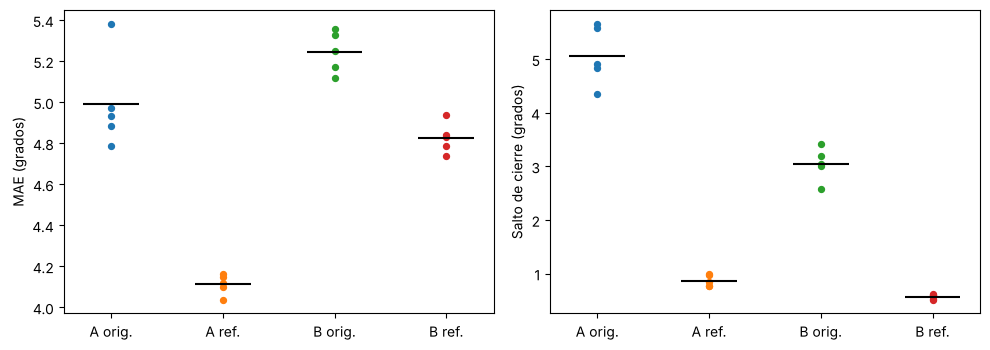

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, metric, label in zip(axes, ("mae_deg", "endpoint_jump_deg"), ("MAE (grados)", "Salto de cierre (grados)")):
    for k, name in enumerate(("A_original", "A_refined", "B_original", "B_refined")):
        values = [r[metric] for r in results[name] if r["seed"] != "ensemble"]
        ax.scatter([k] * len(values), values, s=18)
        ax.hlines(np.mean(values), k - 0.25, k + 0.25, color="k")
    ax.set_xticks(range(4), ["A orig.", "A ref.", "B orig.", "B ref."])
    ax.set_ylabel(label)
plt.tight_layout()
plt.show()

## 5. Reconstrucción de un ciclo de control de prueba

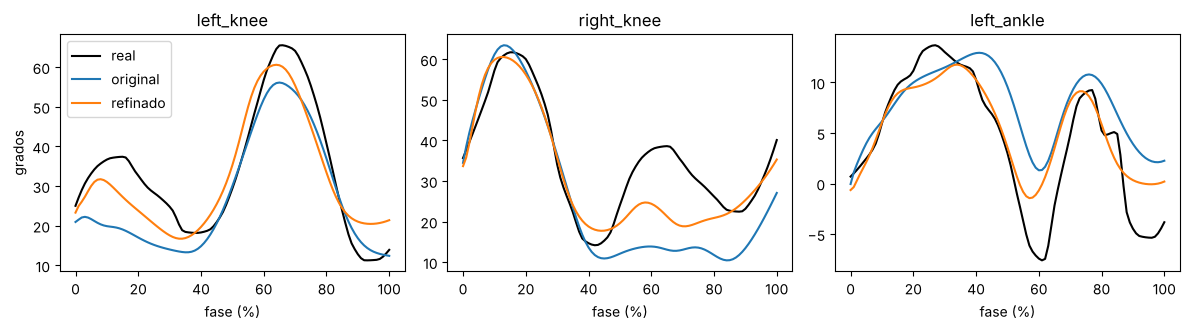

In [6]:
model_o = fit_gru(data, SPECS["A_original"], seed=42)
model_r = fit_gru(data, SPECS["A_refined"], seed=42)
z = data.Z["control_test"][:1]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True)
for j, ax in zip((1, 4, 2), axes):
    ax.plot(data.inverse(z)[0, :, j], "k", label="real")
    ax.plot(data.inverse(predict_gru(model_o, z))[0, :, j], label="original")
    ax.plot(data.inverse(predict_gru(model_r, z))[0, :, j], label="refinado")
    ax.set_title(data.features[j]); ax.set_xlabel("fase (%)")
axes[0].legend(); axes[0].set_ylabel("grados")
plt.tight_layout()
plt.show()